<a href="https://colab.research.google.com/github/Ashwini9713/fundamentals-of-ML/blob/main/exp7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

class LogisticRegressionFromScratch:
    def __init__(self, learning_rate=0.01, num_iterations=1000):
        self.lr = learning_rate
        self.num_iterations = num_iterations
        self.weights = None
        self.bias = None
        self.losses = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        num_samples, num_features = X.shape
        self.weights = np.zeros(num_features)
        self.bias = 0.0
        self.losses = []

        # Gradient Descent
        for i in range(self.num_iterations):
            linear_model = np.dot(X, self.weights) + self.bias
            y_predicted = self._sigmoid(linear_model)

            # Calculate cost (Binary Cross-Entropy)
            # Adding a tiny epsilon to prevent log(0)
            eps = 1e-15
            loss = -1 / num_samples * np.sum(y * np.log(y_predicted + eps) + (1 - y) * np.log(1 - y_predicted + eps))
            self.losses.append(loss)

            # Compute gradients
            dw = (1 / num_samples) * np.dot(X.T, (y_predicted - y))
            db = (1 / num_samples) * np.sum(y_predicted - y)

            # Update parameters
            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict_proba(self, X):
        linear_model = np.dot(X, self.weights) + self.bias
        return self._sigmoid(linear_model)

    def predict(self, X, threshold=0.5):
        probabilities = self.predict_proba(X)
        return np.where(probabilities >= threshold, 1, 0)

Accuracy on Test Set: 87.50%


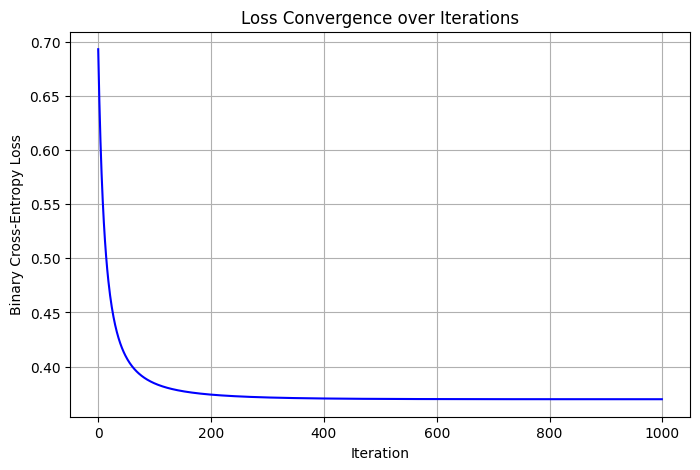

In [2]:
# 1. Generate a synthetic dataset
X, y = make_classification(n_samples=200, n_features=2, n_redundant=0, n_informative=2,
                           random_state=42, n_clusters_per_class=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Train the model
model = LogisticRegressionFromScratch(learning_rate=0.1, num_iterations=1000)
model.fit(X_train, y_train)

# 3. Evaluate predictions
y_pred = model.predict(X_test)
accuracy = np.mean(y_pred == y_test) * 100
print(f"Accuracy on Test Set: {accuracy:.2f}%")

# 4. Plot loss over iterations
plt.figure(figsize=(8, 5))
plt.plot(model.losses, color='blue')
plt.title('Loss Convergence over Iterations')
plt.xlabel('Iteration')
plt.ylabel('Binary Cross-Entropy Loss')
plt.grid(True)
plt.show()